In [1]:

!pip install -q torch torchvision datasets scikit-learn matplotlib seaborn tqdm


In [4]:
import os
import urllib.request
import zipfile

# URL to the official PlantVillage dataset containing the color images
url = "https://github.com/spMohanty/PlantVillage-Dataset/archive/refs/heads/master.zip"
zip_path = "plantvillage.zip"
extract_path = "plantvillage_raw"

# Check if the extracted directory exists; if not, download and extract
if not os.path.exists(extract_path):
    print("Downloading PlantVillage raw dataset (this might take a few minutes)...")
    urllib.request.urlretrieve(url, zip_path)
    print("Download complete. Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction complete!")
else:
    print("Dataset already extracted.")

# Let's inspect the extracted folder path
print("Extracted contents:", os.listdir(extract_path))

Download complete. Extracting dataset...
Extraction complete!
Extracted contents: ['PlantVillage-Dataset-master']


In [5]:
import os

base_dir = os.path.join("plantvillage_raw", "PlantVillage-Dataset-master")
print("Contents of PlantVillage-Dataset-master:", os.listdir(base_dir))

# Let's inspect the 'raw' directory if it exists
raw_dir = os.path.join(base_dir, "raw")
if os.path.exists(raw_dir):
    print("Contents of 'raw' directory:", os.listdir(raw_dir))
    color_dir = os.path.join(raw_dir, "color")
    if os.path.exists(color_dir):
        classes = os.listdir(color_dir)
        print(f"\nFound color directory with {len(classes)} classes.")
        print("Sample classes:", classes[:5])

Contents of PlantVillage-Dataset-master: ['plant_village.py', 'logs', 'utils', 'generated_for_paper', 'generate_lmdb.sh', 'CITATION.cff', 'raw', 'README.md', 'generate_data_for_SVM.py', 'leaf-map.json', 'README_HF.md', 'data_distribution_for_SVM', 'generate_mapstring.py', '.gitignore', 'scripts', 'leaf_grouping']
Contents of 'raw' directory: ['grayscale', 'color', 'segmented']

Found color directory with 38 classes.
Sample classes: ['Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Apple___Black_rot', 'Potato___Late_blight', 'Tomato___Leaf_Mold', 'Blueberry___healthy']


In [6]:
import os
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

BATCH_SIZE = 32
IMAGE_SIZE = 224 # 224 is standard and faster to train than 300

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Training transformations with data augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation and test transformations
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Path to the raw color images
color_dir = "plantvillage_raw/PlantVillage-Dataset-master/raw/color"

# Load full dataset using ImageFolder
full_dataset = datasets.ImageFolder(root=color_dir)
classes = full_dataset.classes
print(f"Total images found: {len(full_dataset)}")
print(f"Number of classes: {len(classes)}")

# Split into Train (70%), Val (15%), Test (15%)
generator = torch.Generator().manual_seed(42)
train_size = int(0.70 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator
)

# Apply transforms by wrapping the split datasets
class TransformedDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = TransformedDataset(train_dataset, train_transform)
val_dataset = TransformedDataset(val_dataset, eval_transform)
test_dataset = TransformedDataset(test_dataset, eval_transform)

# Create Dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Device: cuda
GPU: Tesla T4
Total images found: 54305
Number of classes: 38
Training samples: 38013
Validation samples: 8145
Testing samples: 8147


In [7]:
import os
import torch.nn as nn
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights

# Ensure classes variable is available even if previous cells were not run in this session
if 'classes' not in locals() and 'classes' not in globals():
    color_dir = "plantvillage_raw/PlantVillage-Dataset-master/raw/color"
    if os.path.exists(color_dir):
        classes = sorted(os.listdir(color_dir))
    else:
        raise FileNotFoundError(f"Dataset directory not found at {color_dir}. Please run the preceding cells first.")

NUM_CLASSES = len(classes)

model = efficientnet_b3(
    weights=EfficientNet_B3_Weights.DEFAULT
)

# Replace final classifier
in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES
)

model = model.to(device if 'device' in globals() else torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

print(model.classifier)
print("Model loaded successfully!")
print("Parameters:", sum(p.numel() for p in model.parameters()))

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 125MB/s]


Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1536, out_features=38, bias=True)
)
Model loaded successfully!
Parameters: 10754638


In [8]:

import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 10

print("Training configuration ready.")


Training configuration ready.


In [10]:

from tqdm.auto import tqdm
import copy
import os

best_val_accuracy = 0.0
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

os.makedirs("/content/cerys_models", exist_ok=True)

for epoch in range(EPOCHS):

    # Training
    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images, targets in progress:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == targets).sum().item()
        train_total += targets.size(0)

        progress.set_postfix(loss=loss.item())

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validation
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, targets in val_loader:

            images = images.to(device)
            targets = targets.to(device)

            outputs = model(images)
            loss = criterion(outputs, targets)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == targets).sum().item()
            val_total += targets.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_accuracy)
    history["val_acc"].append(val_accuracy)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": classes,
            "num_classes": NUM_CLASSES,
            "image_size": IMAGE_SIZE
        }, "/content/cerys_models/cerys_efficientnet_b3_best.pth")

        print("Best model checkpoint saved!")

print("\nTraining complete.")
print("Best validation accuracy:", best_val_accuracy)


Epoch 1/10:   0%|          | 0/1188 [00:00<?, ?it/s]


Epoch 1/10
Train Loss: 0.0499
Train Accuracy: 0.9858
Validation Loss: 0.0171
Validation Accuracy: 0.9952
Best model checkpoint saved!


Epoch 2/10:   0%|          | 0/1188 [00:00<?, ?it/s]


Epoch 2/10
Train Loss: 0.0302
Train Accuracy: 0.9910
Validation Loss: 0.0120
Validation Accuracy: 0.9959
Best model checkpoint saved!


Epoch 3/10:   0%|          | 0/1188 [00:00<?, ?it/s]


Epoch 3/10
Train Loss: 0.0237
Train Accuracy: 0.9926
Validation Loss: 0.0108
Validation Accuracy: 0.9967
Best model checkpoint saved!


... (15 outputs left out)


Epoch 9/10
Train Loss: 0.0089
Train Accuracy: 0.9975
Validation Loss: 0.0083
Validation Accuracy: 0.9977


Epoch 10/10:   0%|          | 0/1188 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e7938dcd9e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e7938dcd9e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 10/10
Train Loss: 0.0075
Train Accuracy: 0.9978
Validation Loss: 0.0157
Validation Accuracy: 0.9962

Training complete.
Best validation accuracy: 0.998158379373849


In [11]:

import torch
from torchvision.models import efficientnet_b3
import torch.nn as nn

checkpoint_path = "/content/cerys_models/cerys_efficientnet_b3_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

labels = checkpoint["class_names"]
NUM_CLASSES = checkpoint["num_classes"]

model = efficientnet_b3(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("CeryS model loaded successfully")
print("Number of classes:", NUM_CLASSES)
print("Image size:", checkpoint["image_size"])


CeryS model loaded successfully
Number of classes: 38
Image size: 224


In [12]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import numpy as np

all_predictions = []
all_targets = []

with torch.no_grad():
    for images, targets in tqdm(test_loader):

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(targets.numpy())

accuracy = accuracy_score(all_targets, all_predictions)
macro_f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro"
)

print("TEST ACCURACY:", round(accuracy * 100, 2), "%")
print("MACRO F1:", round(macro_f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    all_targets,
    all_predictions,
    target_names=labels,
    digits=4
))


  0%|          | 0/255 [00:00<?, ?it/s]

TEST ACCURACY: 99.82 %
MACRO F1: 0.9973

Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     1.0000    1.0000    1.0000        91
                                 Apple___Black_rot     1.0000    1.0000    1.0000        87
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        37
                                   Apple___healthy     1.0000    1.0000    1.0000       270
                               Blueberry___healthy     0.9950    1.0000    0.9975       198
          Cherry_(including_sour)___Powdery_mildew     0.9944    1.0000    0.9972       176
                 Cherry_(including_sour)___healthy     1.0000    1.0000    1.0000       125
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9726    1.0000    0.9861        71
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000       168
              

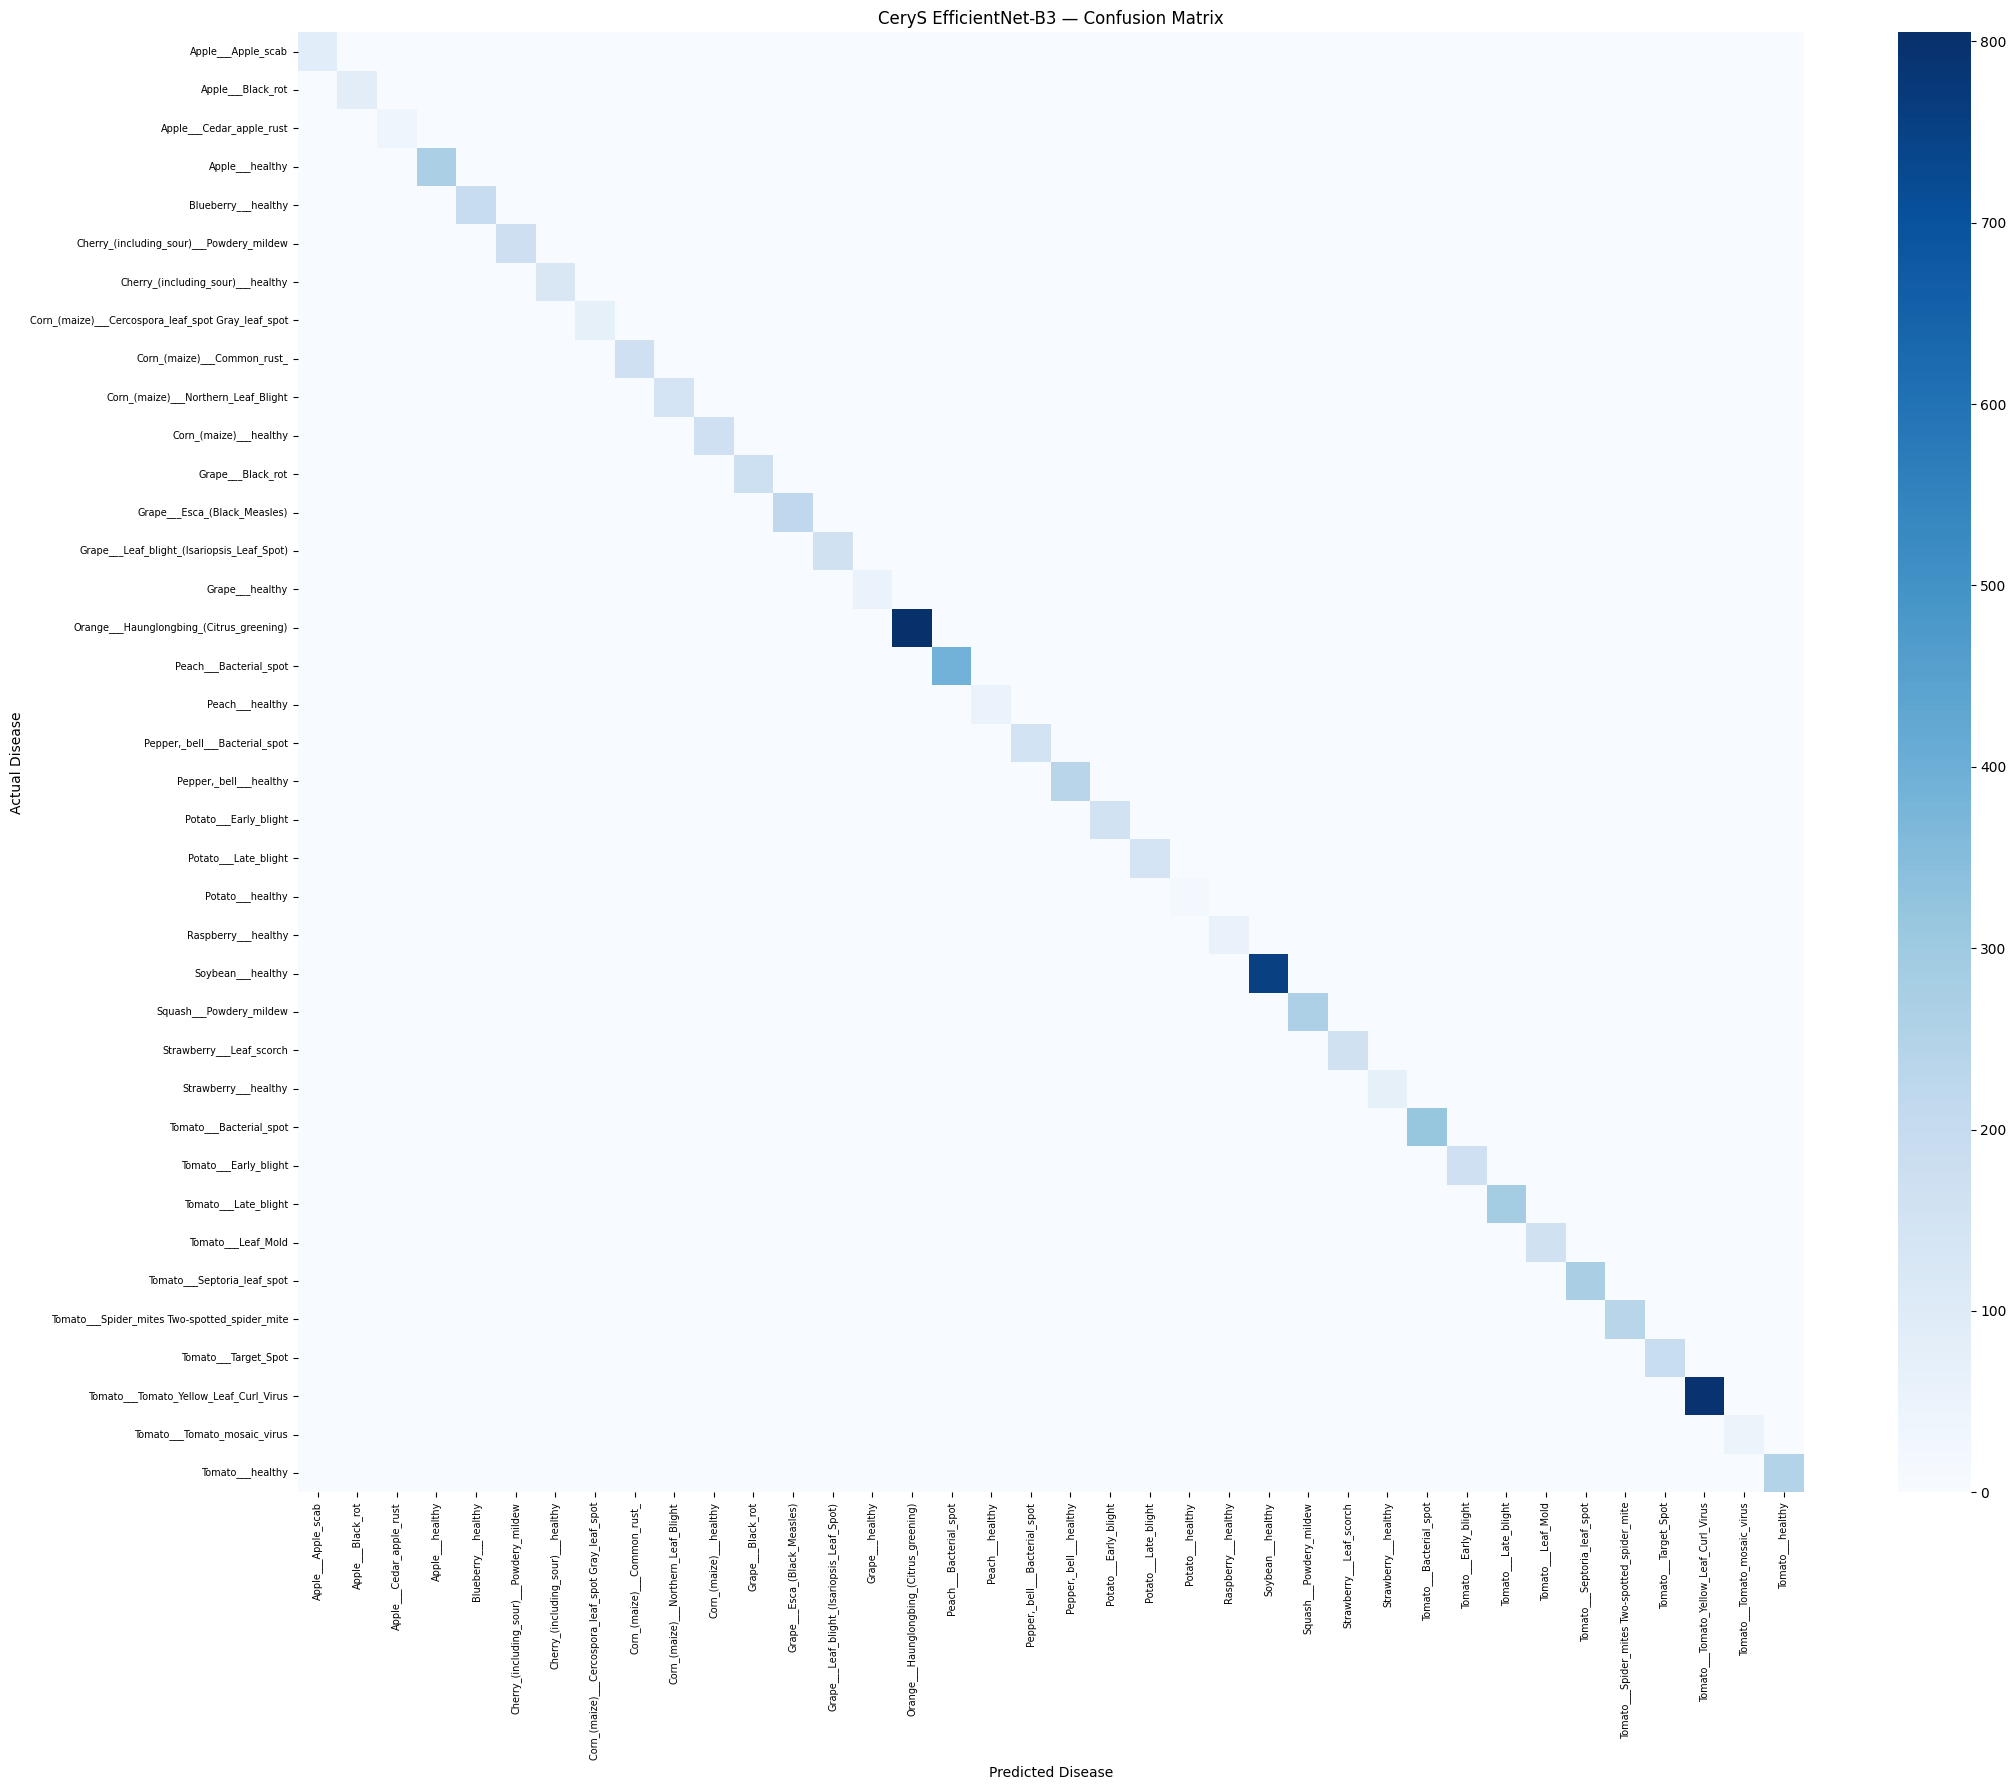

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(all_targets, all_predictions)

plt.figure(figsize=(22, 18))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("CeryS EfficientNet-B3 — Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()


In [14]:

import json
from sklearn.metrics import classification_report

report = classification_report(
    all_targets,
    all_predictions,
    target_names=labels,
    output_dict=True,
    zero_division=0
)

results = {
    "model": "CeryS EfficientNet-B3",
    "dataset": "PlantVillage",
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "classes": labels,
    "classification_report": report
}

with open(
    "/content/cerys_models/evaluation_results.json",
    "w"
) as f:
    json.dump(results, f, indent=4)

print("Evaluation results saved!")


Evaluation results saved!


In [15]:
from google.colab import files

files.download(
    "/content/cerys_models/cerys_efficientnet_b3_best.pth"
)

files.download(
    "/content/cerys_models/evaluation_results.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
!git clone https://github.com/pratikkayal/PlantDoc-Dataset.git /content/PlantDoc

Cloning into '/content/PlantDoc'...
remote: Enumerating objects: 2670, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 2670 (delta 22), reused 22 (delta 22), pack-reused 2635 (from 1)
Receiving objects: 100% (2670/2670), 932.92 MiB | 18.55 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Updating files: 100% (2581/2581), done.


In [17]:
import os

dataset_path = "/content/PlantDoc"

for root, dirs, files in os.walk(dataset_path):
    if files:
        print(root, "->", len(files), "files")

/content/PlantDoc -> 3 files
/content/PlantDoc/test/Apple leaf -> 9 files
/content/PlantDoc/test/Strawberry leaf -> 8 files
/content/PlantDoc/test/grape leaf -> 12 files
/content/PlantDoc/test/Corn Gray leaf spot -> 4 files
/content/PlantDoc/test/Tomato Septoria leaf spot -> 11 files
/content/PlantDoc/test/Tomato leaf bacterial spot -> 9 files
/content/PlantDoc/test/Bell_pepper leaf spot -> 9 files
/content/PlantDoc/test/Blueberry leaf -> 11 files
/content/PlantDoc/test/Squash Powdery mildew leaf -> 6 files
/content/PlantDoc/test/Tomato leaf late blight -> 10 files
/content/PlantDoc/test/grape leaf black rot -> 8 files
/content/PlantDoc/test/Potato leaf late blight -> 8 files
/content/PlantDoc/test/Potato leaf early blight -> 8 files
/content/PlantDoc/test/Tomato leaf yellow virus -> 6 files
/content/PlantDoc/test/Cherry leaf -> 10 files
/content/PlantDoc/test/Tomato Early blight leaf -> 9 files
/content/PlantDoc/test/Tomato leaf -> 8 files
/content/PlantDoc/test/Soyabean leaf -> 8 fil

In [18]:
# Define direct mapping from PlantDoc test categories to PlantVillage 38 classes
# Categories that cannot be reliably mapped are excluded (mapped to None)

plantdoc_to_plantvillage = {
    'Apple leaf': 'Apple___healthy',
    'Apple Scab Leaf': 'Apple___Apple_scab',
    'Apple rust leaf': 'Apple___Cedar_apple_rust',
    'Bell_pepper leaf': 'Pepper,_bell___healthy',
    'Bell_pepper leaf spot': 'Pepper,_bell___Bacterial_spot',
    'Blueberry leaf': 'Blueberry___healthy',
    'Cherry leaf': 'Cherry_(including_sour)___healthy',
    'Corn leaf blight': 'Corn_(maize)___Northern_Leaf_Blight',
    'Corn Gray leaf spot': 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
    'Corn rust leaf': 'Corn_(maize)___Common_rust_',
    'grape leaf': 'Grape___healthy',
    'grape leaf black rot': 'Grape___Black_rot',
    'Peach leaf': 'Peach___healthy',
    'Potato leaf early blight': 'Potato___Early_blight',
    'Potato leaf late blight': 'Potato___Late_blight',
    'Raspberry leaf': 'Raspberry___healthy',
    'Soyabean leaf': 'Soybean___healthy',
    'Squash Powdery mildew leaf': 'Squash___Powdery_mildew',
    'Strawberry leaf': 'Strawberry___healthy',
    'Tomato leaf': 'Tomato___healthy',
    'Tomato Early blight leaf': 'Tomato___Early_blight',
    'Tomato leaf bacterial spot': 'Tomato___Bacterial_spot',
    'Tomato leaf late blight': 'Tomato___Late_blight',
    'Tomato leaf mosaic virus': 'Tomato___Tomato_mosaic_virus',
    'Tomato leaf yellow virus': 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
    'Tomato mold leaf': 'Tomato___Leaf_Mold',
    'Tomato Septoria leaf spot': 'Tomato___Septoria_leaf_spot'
}

# Filter out categories mapped to None, and build class-to-index mapper based on model classes
model_class_to_idx = {cls: idx for idx, cls in enumerate(labels)}

print(f"Mapped {len(plantdoc_to_plantvillage)} PlantDoc categories to PlantVillage.")

Mapped 27 PlantDoc categories to PlantVillage.


In [19]:
import torch
from torchvision import transforms
from PIL import Image
import os

# Create a manual test dataset loader for mapped PlantDoc test images
plantdoc_test_dir = "/content/PlantDoc/test"
test_images = []
test_targets = []

# Define evaluation transform (same as evaluation pipeline)
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

for cat_dir in os.listdir(plantdoc_test_dir):
    full_cat_path = os.path.join(plantdoc_test_dir, cat_dir)
    if not os.path.isdir(full_cat_path):
        continue

    # Get target class name in PlantVillage
    pv_class = plantdoc_to_plantvillage.get(cat_dir)
    if pv_class is None or pv_class not in model_class_to_idx:
        print(f"Skipping unmapped directory: {cat_dir}")
        continue

    target_idx = model_class_to_idx[pv_class]

    for img_name in os.listdir(full_cat_path):
        img_path = os.path.join(full_cat_path, img_name)
        try:
            with Image.open(img_path) as img:
                # Convert to RGB to ensure 3 channels
                img_tensor = eval_transform(img.convert("RGB"))
                test_images.append(img_tensor)
                test_targets.append(target_idx)
        except Exception as e:
            # Handle potentially corrupted files
            continue

print(f"Loaded {len(test_images)} valid images matching mapped categories.")

Loaded 236 valid images matching mapped categories.


In [20]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report, f1_score
import numpy as np

# Build a PyTorch Dataset and DataLoader
plantdoc_dataset = TensorDataset(torch.stack(test_images), torch.tensor(test_targets))
plantdoc_loader = DataLoader(plantdoc_dataset, batch_size=32, shuffle=False, num_workers=2)

plantdoc_preds = []
plantdoc_actuals = []

model.eval()
with torch.no_grad():
    for imgs, targets in plantdoc_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        predictions = outputs.argmax(dim=1)

        plantdoc_preds.extend(predictions.cpu().numpy())
        plantdoc_actuals.extend(targets.numpy())

# Calculate metrics using target names subset that are actually present in our evaluation dataset
unique_targets = sorted(list(set(plantdoc_actuals)))
mapped_labels = [labels[idx] for idx in unique_targets]

accuracy = accuracy_score(plantdoc_actuals, plantdoc_preds)
macro_f1 = f1_score(plantdoc_actuals, plantdoc_preds, average="macro")

print(f"EXTERNAL ACCURACY ON PLANTDOC: {round(accuracy * 100, 2)}%")
print(f"MACRO F1 ON PLANTDOC: {round(macro_f1, 4)}\n")

print("Classification Report on PlantDoc Dataset:\n")
print(classification_report(
    plantdoc_actuals,
    plantdoc_preds,
    labels=unique_targets,
    target_names=mapped_labels,
    zero_division=0
))

EXTERNAL ACCURACY ON PLANTDOC: 30.08%
MACRO F1 ON PLANTDOC: 0.2247

Classification Report on PlantDoc Dataset:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.50      0.10      0.17        10
                          Apple___Cedar_apple_rust       0.33      0.10      0.15        10
                                   Apple___healthy       0.50      0.22      0.31         9
                               Blueberry___healthy       0.29      0.45      0.36        11
                 Cherry_(including_sour)___healthy       0.25      0.10      0.14        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.17      0.50      0.25         4
                       Corn_(maize)___Common_rust_       0.00      0.00      0.00        10
               Corn_(maize)___Northern_Leaf_Blight       0.38      0.42      0.40        12
                                 Grape___Black_rot       0.

In [21]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print("Number of actual labels:", len(all_targets))
print("Number of predictions:", len(all_predictions))

print(
    "Accuracy:",
    accuracy_score(all_targets, all_predictions)
)

print(
    "Macro F1:",
    f1_score(
        all_targets,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

print(
    "Micro F1:",
    f1_score(
        all_targets,
        all_predictions,
        average="micro",
        zero_division=0
    )
)

print("\nVerified classification report:")

print(
    classification_report(
        all_targets,
        all_predictions,
        digits=4,
        zero_division=0
    )
)

Number of actual labels: 8147
Number of predictions: 8147
Accuracy: 0.9981588314717074
Macro F1: 0.9973087490725339
Micro F1: 0.9981588314717074

Verified classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        91
           1     1.0000    1.0000    1.0000        87
           2     1.0000    1.0000    1.0000        37
           3     1.0000    1.0000    1.0000       270
           4     0.9950    1.0000    0.9975       198
           5     0.9944    1.0000    0.9972       176
           6     1.0000    1.0000    1.0000       125
           7     0.9726    1.0000    0.9861        71
           8     1.0000    1.0000    1.0000       168
           9     1.0000    0.9796    0.9897       147
          10     0.9941    1.0000    0.9970       168
          11     1.0000    1.0000    1.0000       171
          12     1.0000    1.0000    1.0000       220
          13     1.0000    1.0000    1.0000       159
          1

In [23]:
from sklearn.metrics import accuracy_score, f1_score

# Using the correct variable names from your evaluation cell
print("PlantDoc samples:", len(plantdoc_actuals))
print("PlantDoc predictions:", len(plantdoc_preds))

print("PlantDoc accuracy:",
      accuracy_score(plantdoc_actuals, plantdoc_preds))

print("PlantDoc macro F1:",
      f1_score(
          plantdoc_actuals,
          plantdoc_preds,
          average="macro",
          zero_division=0
      ))

print("PlantDoc micro F1:",
      f1_score(
          plantdoc_actuals,
          plantdoc_preds,
          average="micro",
          zero_division=0
      ))

PlantDoc samples: 236
PlantDoc predictions: 236
PlantDoc accuracy: 0.3008474576271186
PlantDoc macro F1: 0.22467828467828468
PlantDoc micro F1: 0.3008474576271186


In [25]:
from collections import Counter

print("Actual PlantDoc classes:")
print(Counter(plantdoc_actuals))

print("\nPredicted PlantDoc classes:")
print(Counter(plantdoc_preds))

Actual PlantDoc classes:
Counter({np.int64(14): 12, np.int64(9): 12, np.int64(32): 11, np.int64(4): 11, np.int64(30): 10, np.int64(6): 10, np.int64(0): 10, np.int64(8): 10, np.int64(2): 10, np.int64(36): 10, np.int64(3): 9, np.int64(28): 9, np.int64(18): 9, np.int64(29): 9, np.int64(17): 9, np.int64(27): 8, np.int64(11): 8, np.int64(21): 8, np.int64(20): 8, np.int64(37): 8, np.int64(24): 8, np.int64(19): 8, np.int64(23): 7, np.int64(25): 6, np.int64(35): 6, np.int64(31): 6, np.int64(7): 4})

Predicted PlantDoc classes:
Counter({np.int64(30): 23, np.int64(14): 21, np.int64(29): 18, np.int64(4): 17, np.int64(32): 15, np.int64(9): 13, np.int64(7): 12, np.int64(25): 12, np.int64(26): 9, np.int64(15): 8, np.int64(19): 8, np.int64(23): 7, np.int64(16): 7, np.int64(20): 7, np.int64(12): 5, np.int64(18): 5, np.int64(11): 5, np.int64(6): 4, np.int64(3): 4, np.int64(35): 4, np.int64(21): 4, np.int64(1): 4, np.int64(24): 3, np.int64(31): 3, np.int64(2): 3, np.int64(10): 3, np.int64(27): 2, np.int

In [27]:
import pandas as pd

errors = []

# Correcting variable names to plantdoc_actuals and plantdoc_preds
for actual, predicted in zip(
    plantdoc_actuals,
    plantdoc_preds
):
    if actual != predicted:
        errors.append({
            "Actual": labels[actual],
            "Predicted": labels[predicted]
        })

error_df = pd.DataFrame(errors)

print("Total incorrect predictions:", len(error_df))
print("\nMost frequent errors:")

print(
    error_df.value_counts(
        ["Actual", "Predicted"]
    ).head(15)
)

Total incorrect predictions: 165

Most frequent errors:
Actual                                  Predicted                                         
Corn_(maize)___Common_rust_             Corn_(maize)___Northern_Leaf_Blight                   7
Corn_(maize)___Northern_Leaf_Blight     Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    6
Strawberry___healthy                    Grape___healthy                                       6
Soybean___healthy                       Blueberry___healthy                                   5
Apple___healthy                         Blueberry___healthy                                   3
Corn_(maize)___Common_rust_             Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    3
Tomato___healthy                        Tomato___Late_blight                                  3
Tomato___Tomato_Yellow_Leaf_Curl_Virus  Squash___Powdery_mildew                               3
Tomato___Bacterial_spot                 Tomato___Septoria_leaf_spot                  

In [28]:
import os
import torch
from PIL import Image
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Only explicitly labelled disease categories
strict_mapping = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "grape leaf black rot": "Grape___Black_rot",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot"
}

model_class_to_idx = {
    name: idx for idx, name in enumerate(labels)
}

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

strict_images = []
strict_targets = []

test_dir = "/content/PlantDoc/test"

for folder, target_class in strict_mapping.items():

    folder_path = os.path.join(test_dir, folder)

    if not os.path.isdir(folder_path):
        continue

    if target_class not in model_class_to_idx:
        continue

    target_idx = model_class_to_idx[target_class]

    for filename in os.listdir(folder_path):

        image_path = os.path.join(folder_path, filename)

        try:
            with Image.open(image_path) as img:
                image_tensor = transform(img.convert("RGB"))

            strict_images.append(image_tensor)
            strict_targets.append(target_idx)

        except Exception:
            continue

# Run inference without modifying the model
strict_predictions = []

model.eval()

with torch.no_grad():
    for i in range(0, len(strict_images), 32):

        batch = torch.stack(
            strict_images[i:i + 32]
        ).to(device)

        outputs = model(batch)

        predictions = outputs.argmax(dim=1)

        strict_predictions.extend(
            predictions.cpu().numpy()
        )

print("External test images:", len(strict_targets))

print(
    "Strict PlantDoc accuracy:",
    accuracy_score(strict_targets, strict_predictions)
)

print(
    "Strict PlantDoc macro F1:",
    f1_score(
        strict_targets,
        strict_predictions,
        average="macro",
        zero_division=0
    )
)

print("\nClassification report:\n")

print(
    classification_report(
        strict_targets,
        strict_predictions,
        labels=sorted(set(strict_targets)),
        target_names=[
            labels[i] for i in sorted(set(strict_targets))
        ],
        zero_division=0,
        digits=4
    )
)

External test images: 134
Strict PlantDoc accuracy: 0.2537313432835821
Strict PlantDoc macro F1: 0.14774405670957394

Classification report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.5000    0.1000    0.1667        10
                          Apple___Cedar_apple_rust     0.5000    0.1000    0.1667        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.3333    0.5000    0.4000         4
                       Corn_(maize)___Common_rust_     0.0000    0.0000    0.0000        10
                                 Grape___Black_rot     0.8000    0.5000    0.6154         8
                     Pepper,_bell___Bacterial_spot     0.6000    0.3333    0.4286         9
                             Potato___Early_blight     0.2857    0.2500    0.2667         8
                              Potato___Late_blight     0.0000    0.0000    0.0000         8
                           Sq

In [29]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# The 16 categories represented in the strict test set
target_classes = sorted(set(strict_targets))

print("Accuracy:",
      accuracy_score(strict_targets, strict_predictions))

print("Macro F1 across 16 evaluated categories:",
      f1_score(
          strict_targets,
          strict_predictions,
          labels=target_classes,
          average="macro",
          zero_division=0
      ))

print("\nClassification report:")

print(classification_report(
    strict_targets,
    strict_predictions,
    labels=target_classes,
    target_names=[labels[i] for i in target_classes],
    zero_division=0,
    digits=4
))

# Predictions outside the 16 evaluated categories
outside = [
    p for p in strict_predictions
    if p not in target_classes
]

print("\nPredictions outside evaluated categories:", len(outside))
print("Total predictions:", len(strict_predictions))

Accuracy: 0.2537313432835821
Macro F1 across 16 evaluated categories: 0.2677861027861028

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.5000    0.1000    0.1667        10
                          Apple___Cedar_apple_rust     0.5000    0.1000    0.1667        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.3333    0.5000    0.4000         4
                       Corn_(maize)___Common_rust_     0.0000    0.0000    0.0000        10
                                 Grape___Black_rot     0.8000    0.5000    0.6154         8
                     Pepper,_bell___Bacterial_spot     0.6000    0.3333    0.4286         9
                             Potato___Early_blight     0.2857    0.2500    0.2667         8
                              Potato___Late_blight     0.0000    0.0000    0.0000         8
                           Squash___Powdery_mildew     0.5

In [30]:
import os

train_dir = "/content/PlantDoc/train"

print("PlantDoc training categories:\n")

for folder in sorted(os.listdir(train_dir)):
    folder_path = os.path.join(train_dir, folder)

    if os.path.isdir(folder_path):
        count = sum(
            1 for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )
        if folder in strict_mapping:
            print(f"{folder}: {count} images")

PlantDoc training categories:

Apple Scab Leaf: 83 images
Apple rust leaf: 79 images
Bell_pepper leaf spot: 62 images
Corn Gray leaf spot: 64 images
Corn rust leaf: 106 images
Potato leaf early blight: 109 images
Potato leaf late blight: 97 images
Squash Powdery mildew leaf: 124 images
Tomato Early blight leaf: 79 images
Tomato Septoria leaf spot: 140 images
Tomato leaf bacterial spot: 101 images
Tomato leaf late blight: 101 images
Tomato leaf mosaic virus: 44 images
Tomato leaf yellow virus: 70 images
Tomato mold leaf: 85 images
grape leaf black rot: 56 images


In [31]:

import os
import copy
import numpy as np
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# 1. Save the original model separately
os.makedirs("/content/cerys_models", exist_ok=True)

torch.save(
    model.state_dict(),
    "/content/cerys_models/plantvillage_baseline.pth"
)

# 2. Map PlantDoc labels to existing PlantVillage classes
strict_mapping = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "grape leaf black rot": "Grape___Black_rot"
}

class_to_idx = {name: i for i, name in enumerate(labels)}

# 3. Collect PlantDoc training images
train_dir = "/content/PlantDoc/train"
records = []

for folder, target_name in strict_mapping.items():
    folder_path = os.path.join(train_dir, folder)

    if not os.path.isdir(folder_path):
        print("Missing folder:", folder)
        continue

    if target_name not in class_to_idx:
        print("Missing model class:", target_name)
        continue

    target = class_to_idx[target_name]

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            records.append((
                os.path.join(folder_path, filename),
                target
            ))

print("Total training images:", len(records))

# 4. Create training and validation split
indices = np.arange(len(records))
targets = np.array([target for _, target in records])

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=targets
)

class PlantDocDataset(Dataset):
    def __init__(self, records, indices, transform):
        self.records = records
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        path, target = self.records[self.indices[index]]

        with Image.open(path) as img:
            image = img.convert("RGB")

        return self.transform(image), target

# 5. Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_dataset = PlantDocDataset(records, train_indices, train_transform)
val_dataset = PlantDocDataset(records, val_indices, val_transform)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True,
    num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False,
    num_workers=2, pin_memory=True
)

# 6. Freeze early layers and fine-tune the final feature blocks
for parameter in model.parameters():
    parameter.requires_grad = False

for parameter in model.features[7:].parameters():
    parameter.requires_grad = True

for parameter in model.classifier.parameters():
    parameter.requires_grad = True

# 7. Optimizer and loss
train_targets = targets[train_indices]
counts = np.bincount(train_targets, minlength=len(labels))
present_classes = np.where(counts > 0)[0]

class_weights = np.zeros(len(labels), dtype=np.float32)
class_weights[present_classes] = (
    len(train_targets) /
    (len(present_classes) * counts[present_classes])
)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32).to(device)
)

optimizer = torch.optim.AdamW([
    {"params": model.features[7:].parameters(), "lr": 1e-5},
    {"params": model.classifier.parameters(), "lr": 1e-4}
], weight_decay=1e-4)

# 8. Training and validation
best_f1 = 0
best_state = copy.deepcopy(model.state_dict())
epochs = 8

model.to(device)

for epoch in range(epochs):

    model.train()
    running_loss = 0

    for images, targets_batch in train_loader:
        images = images.to(device)
        targets_batch = targets_batch.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, targets_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    model.eval()
    actuals = []
    predictions = []

    with torch.no_grad():
        for images, targets_batch in val_loader:
            images = images.to(device)

            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()

            predictions.extend(preds)
            actuals.extend(targets_batch.numpy())

    val_accuracy = accuracy_score(actuals, predictions)

    val_f1 = f1_score(
        actuals,
        predictions,
        labels=present_classes,
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {running_loss/len(train_loader):.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f} | "
        f"Validation Macro F1: {val_f1:.4f}"
    )

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            "/content/cerys_models/cerys_plantdoc_finetuned.pth"
        )

# 9. Load the best validation checkpoint
model.load_state_dict(best_state)

print("\nFine-tuning complete.")
print("Best validation macro F1:", round(best_f1, 4))
print("Saved: /content/cerys_models/cerys_plantdoc_finetuned.pth")


Total training images: 1400
Epoch 1/8 | Loss: 3.6056 | Validation Accuracy: 0.2571 | Validation Macro F1: 0.2918
Epoch 2/8 | Loss: 3.0105 | Validation Accuracy: 0.2857 | Validation Macro F1: 0.3043
Epoch 3/8 | Loss: 2.6206 | Validation Accuracy: 0.3250 | Validation Macro F1: 0.3355
Epoch 4/8 | Loss: 2.3081 | Validation Accuracy: 0.3500 | Validation Macro F1: 0.3536
Epoch 5/8 | Loss: 2.1920 | Validation Accuracy: 0.3821 | Validation Macro F1: 0.3823
Epoch 6/8 | Loss: 2.0515 | Validation Accuracy: 0.4107 | Validation Macro F1: 0.4096
Epoch 7/8 | Loss: 1.9483 | Validation Accuracy: 0.4143 | Validation Macro F1: 0.4097
Epoch 8/8 | Loss: 1.8073 | Validation Accuracy: 0.4393 | Validation Macro F1: 0.4314

Fine-tuning complete.
Best validation macro F1: 0.4314
Saved: /content/cerys_models/cerys_plantdoc_finetuned.pth


In [32]:

import os
import torch
from PIL import Image
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Load best fine-tuned checkpoint
model.load_state_dict(
    torch.load(
        "/content/cerys_models/cerys_plantdoc_finetuned.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

test_dir = "/content/PlantDoc/test"

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_images = []
test_targets = []

for folder, target_name in strict_mapping.items():

    folder_path = os.path.join(test_dir, folder)

    if not os.path.isdir(folder_path):
        continue

    target_idx = class_to_idx[target_name]

    for filename in os.listdir(folder_path):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            path = os.path.join(folder_path, filename)

            try:
                with Image.open(path) as img:
                    image = test_transform(img.convert("RGB"))

                test_images.append(image)
                test_targets.append(target_idx)

            except Exception:
                continue

test_predictions = []

with torch.no_grad():
    for i in range(0, len(test_images), 16):

        batch = torch.stack(
            test_images[i:i+16]
        ).to(device)

        outputs = model(batch)

        test_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )

test_classes = sorted(set(test_targets))

print("External test images:", len(test_targets))

print(
    "Test accuracy:",
    accuracy_score(test_targets, test_predictions)
)

print(
    "Test macro F1:",
    f1_score(
        test_targets,
        test_predictions,
        labels=test_classes,
        average="macro",
        zero_division=0
    )
)

print("\nClassification report:")

print(classification_report(
    test_targets,
    test_predictions,
    labels=test_classes,
    target_names=[labels[i] for i in test_classes],
    zero_division=0,
    digits=4
))


External test images: 134
Test accuracy: 0.47761194029850745
Test macro F1: 0.5022695232399179

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.8333    0.5000    0.6250        10
                          Apple___Cedar_apple_rust     0.8000    0.8000    0.8000        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.6667    0.5000    0.5714         4
                       Corn_(maize)___Common_rust_     0.8000    0.8000    0.8000        10
                                 Grape___Black_rot     1.0000    0.8750    0.9333         8
                     Pepper,_bell___Bacterial_spot     0.4000    0.4444    0.4211         9
                             Potato___Early_blight     0.3000    0.3750    0.3333         8
                              Potato___Late_blight     0.3077    0.5000    0.3810         8
                           Squash___Powdery_mildew  

In [33]:
from collections import Counter

evaluated_classes = set(test_targets)

outside_predictions = [
    p for p in test_predictions
    if p not in evaluated_classes
]

print("Total test images:", len(test_targets))
print("Predictions outside 16 categories:", len(outside_predictions))
print("Percentage:", round(
    len(outside_predictions) / len(test_predictions) * 100, 2
), "%")

print("\nMost frequent outside predictions:")
for class_idx, count in Counter(outside_predictions).most_common(10):
    print(labels[class_idx], ":", count)

Total test images: 134
Predictions outside 16 categories: 9
Percentage: 6.72 %

Most frequent outside predictions:
Orange___Haunglongbing_(Citrus_greening) : 4
Soybean___healthy : 2
Blueberry___healthy : 1
Corn_(maize)___Northern_Leaf_Blight : 1
Strawberry___healthy : 1


In [35]:
from google.colab import files

files.download(
    "/content/cerys_models/cerys_plantdoc_finetuned.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import torch
import os
from google.colab import files

final_path = "/content/cerys_models/CeryS_EfficientNetB3_PlantDoc_v1.pth"

final_package = {
    "model_name": "CeryS EfficientNet-B3",
    "version": "1.0",
    "architecture": "efficientnet_b3",
    "model_state_dict": model.state_dict(),
    "class_names": labels,
    "num_classes": len(labels),
    "image_size": 224,
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "fine_tuned_on": "PlantDoc training split",
    "external_test": {
        "dataset": "PlantDoc",
        "images": 134,
        "accuracy": 0.47761194029850745,
        "macro_f1": 0.5022695232399179
    },
    "limitations": [
        "Experimental research model",
        "Not validated for production diagnosis",
        "External evaluation limited to 16 mapped disease categories"
    ]
}

torch.save(final_package, final_path)

print("Final model package saved:", final_path)
print("Model classes:", len(labels))
print("File size:", round(os.path.getsize(final_path) / (1024 * 1024), 2), "MB")

files.download(final_path)

Final model package saved: /content/cerys_models/CeryS_EfficientNetB3_PlantDoc_v1.pth
Model classes: 38
File size: 41.57 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving leaf 2'.jpg to leaf 2'.jpg


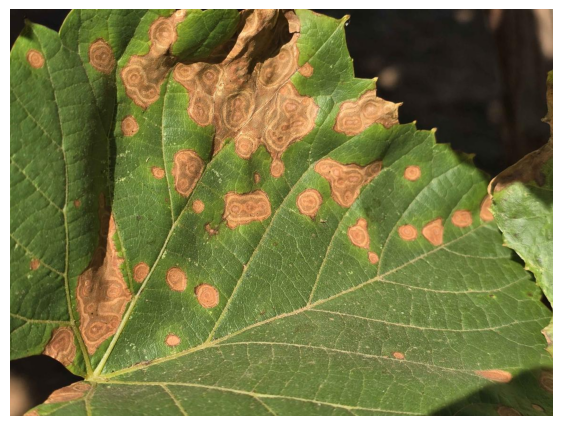

TOP 3 MODEL PREDICTIONS

1. Apple___Cedar_apple_rust — 65.50%
2. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot — 16.24%
3. Pepper,_bell___Bacterial_spot — 11.30%


In [38]:

import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import models, transforms
from google.colab import files
import matplotlib.pyplot as plt

# Load final model package
checkpoint = torch.load(
    "/content/cerys_models/CeryS_EfficientNetB3_PlantDoc_v1.pth",
    map_location=device,
    weights_only=False
)

# Reconstruct EfficientNet-B3
test_model = models.efficientnet_b3(weights=None)
test_model.classifier[1] = torch.nn.Linear(
    test_model.classifier[1].in_features,
    checkpoint["num_classes"]
)

test_model.load_state_dict(checkpoint["model_state_dict"])
test_model.to(device)
test_model.eval()

labels_final = checkpoint["class_names"]

# Upload downloaded Google Images photograph
uploaded = files.upload()
image_path = next(iter(uploaded))

# Apply model's evaluation transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        checkpoint["normalization_mean"],
        checkpoint["normalization_std"]
    )
])

image = Image.open(image_path).convert("RGB")
image_tensor = transform(image).unsqueeze(0).to(device)

# Predict
with torch.no_grad():
    outputs = test_model(image_tensor)
    probabilities = F.softmax(outputs, dim=1)[0]

top_values, top_indices = torch.topk(probabilities, 3)

# Display photograph
plt.figure(figsize=(7, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

print("TOP 3 MODEL PREDICTIONS\n")

for rank, (value, index) in enumerate(
    zip(top_values.cpu(), top_indices.cpu()), 1
):
    print(
        f"{rank}. {labels_final[index]} "
        f"— {value.item() * 100:.2f}%"
    )


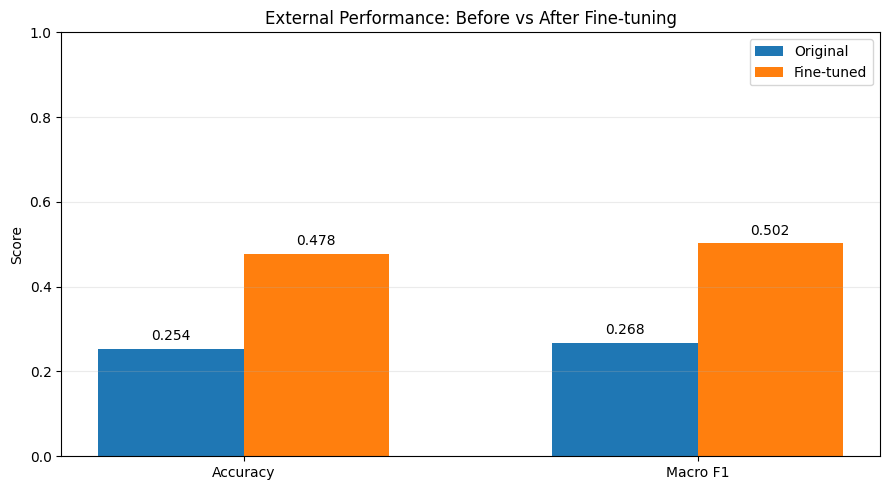

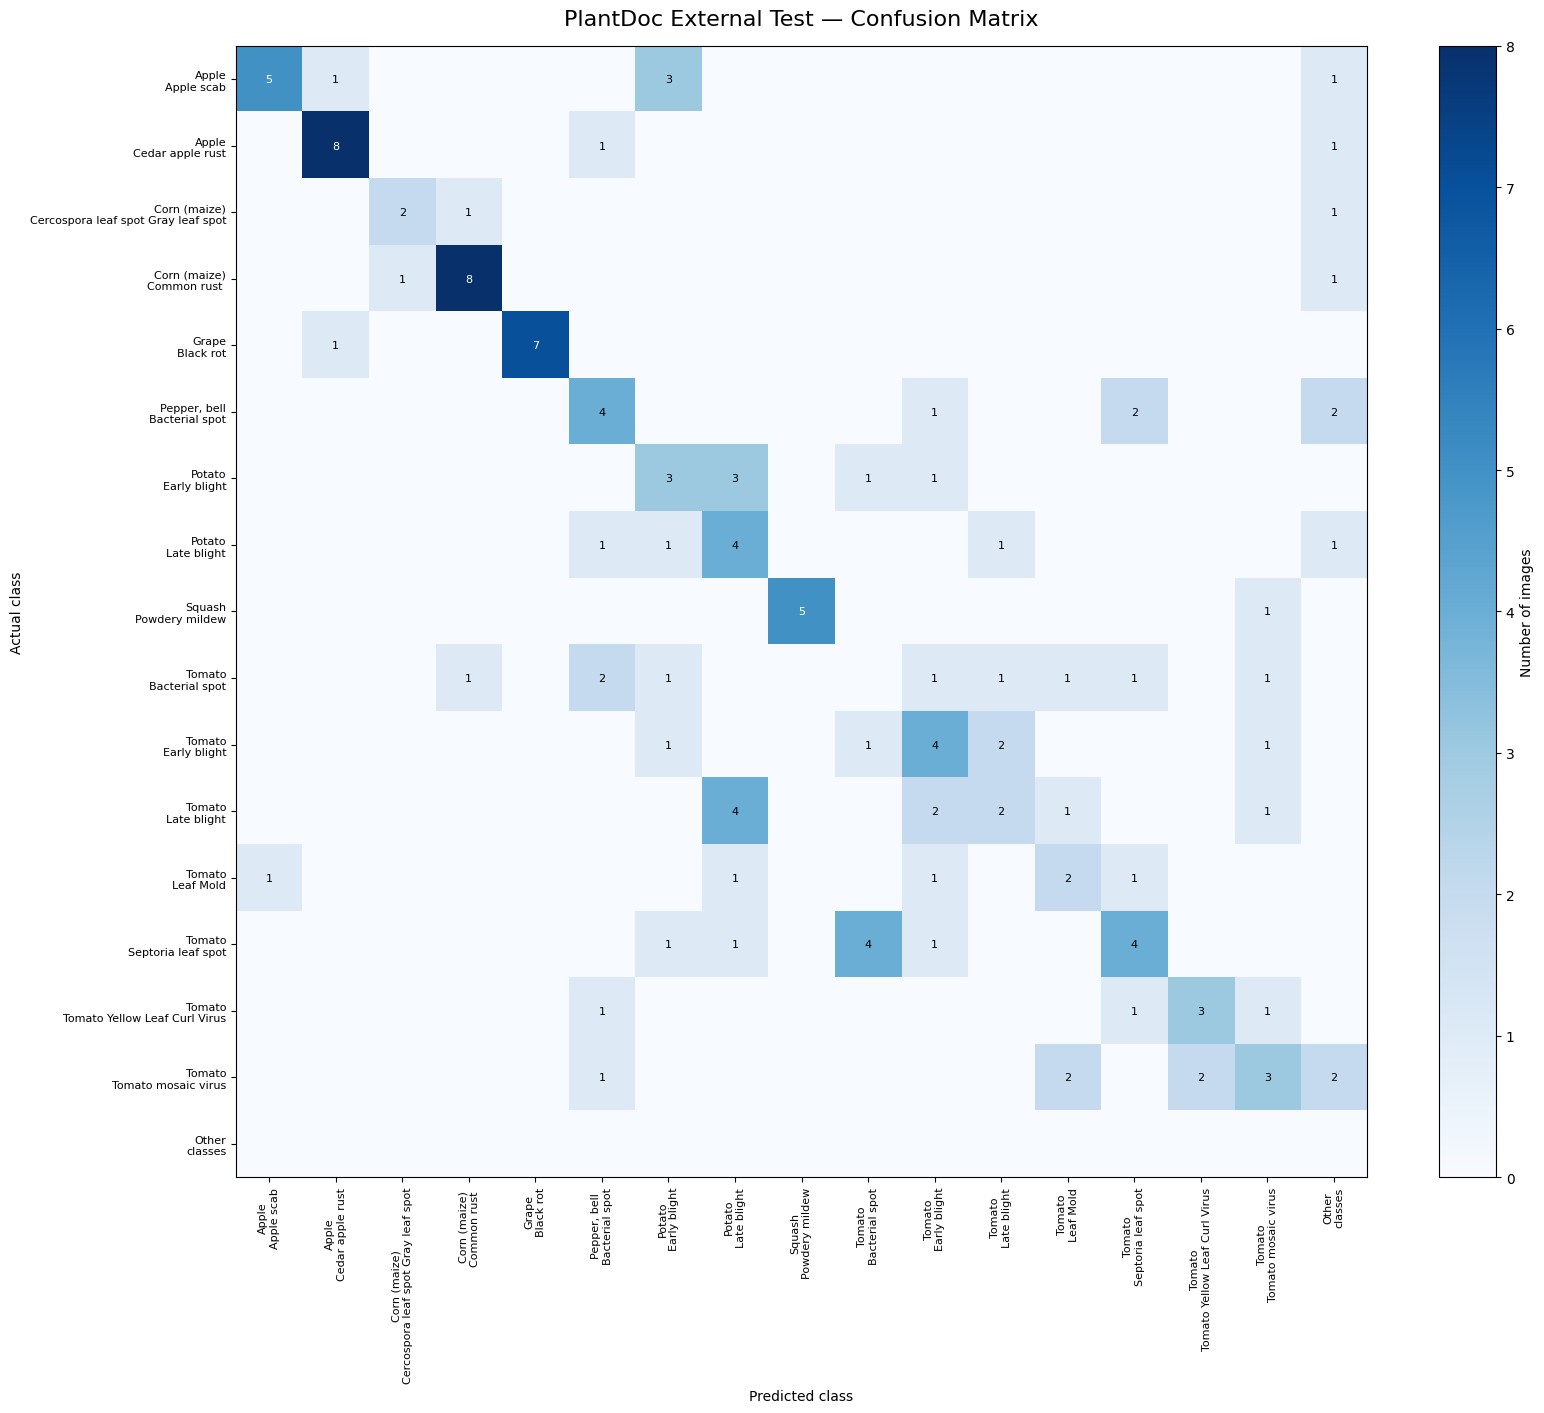

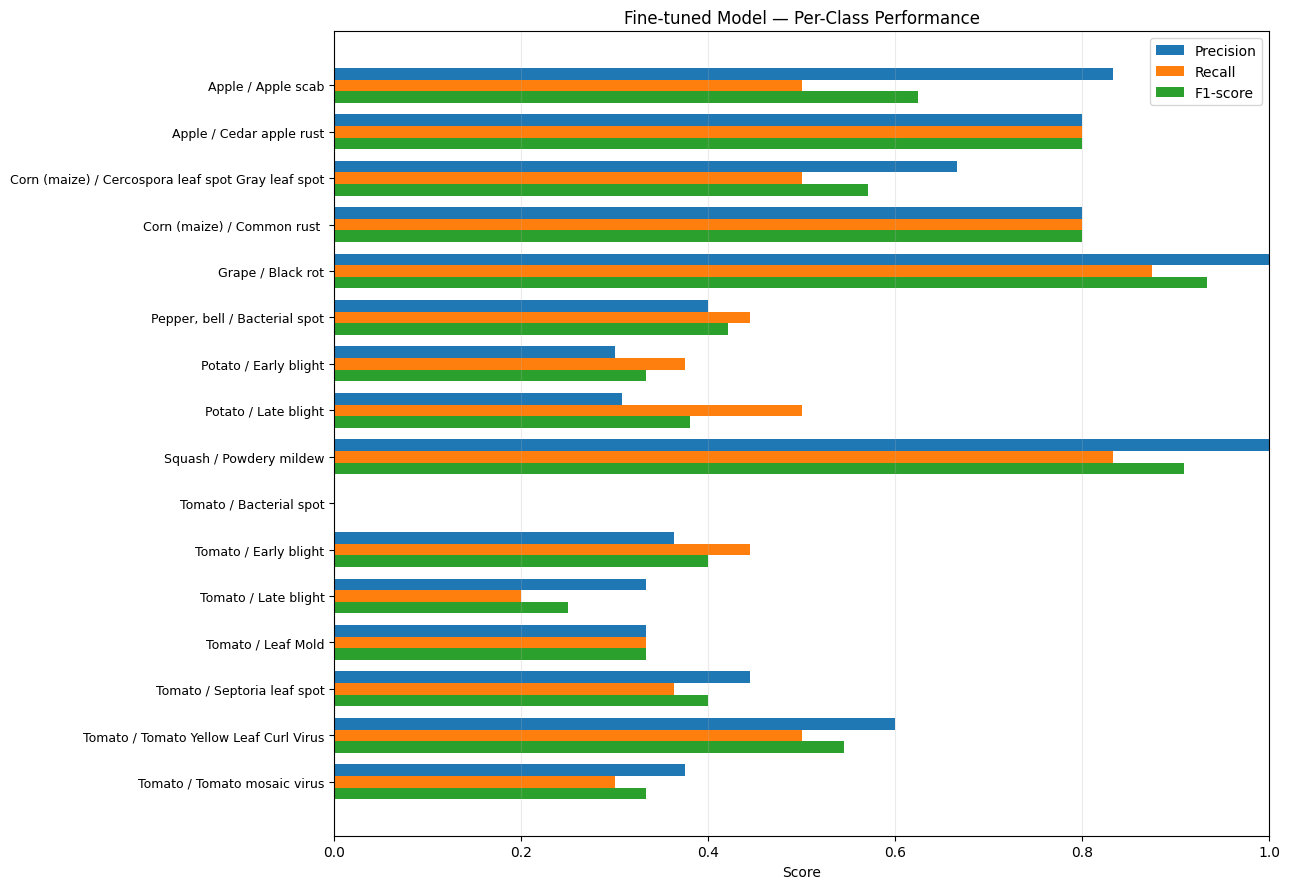

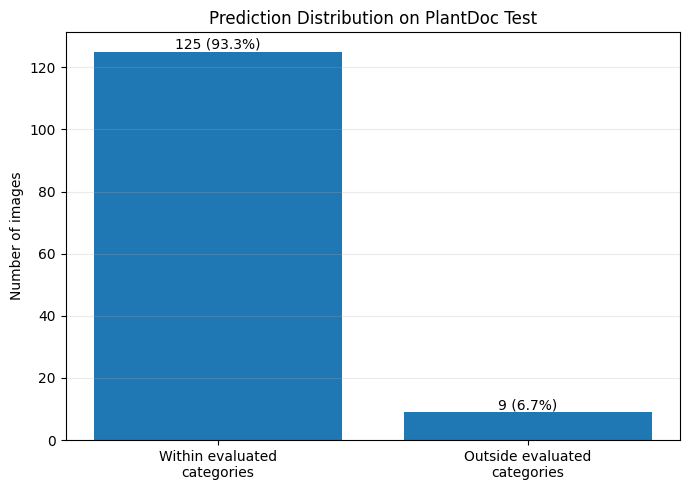


CeryS EfficientNet-B3 — Experimental v1

PlantVillage test accuracy: 99.82%
PlantVillage macro F1: 0.9973

PlantDoc original accuracy: 0.2537
PlantDoc original macro F1: 0.2678

PlantDoc fine-tuned accuracy: 0.4776
PlantDoc fine-tuned macro F1: 0.5023

PlantDoc external test images: 134
Predictions within evaluated categories: 125
Predictions outside evaluated categories: 9

Fine-tuning:
Training images: 1,400
Training/validation split: 80/20
Epochs: 8
Architecture: EfficientNet-B3
Input size: 224x224

Visualizations saved to: /content/cerys_visualizations


In [39]:

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

# Create output directory
OUTPUT_DIR = "/content/cerys_visualizations"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --------------------------------------------------
# 1. PERFORMANCE COMPARISON
# --------------------------------------------------

original_accuracy = accuracy_score(
    strict_targets, strict_predictions
)

original_f1 = f1_score(
    strict_targets,
    strict_predictions,
    labels=sorted(set(strict_targets)),
    average="macro",
    zero_division=0
)

finetuned_accuracy = accuracy_score(
    test_targets, test_predictions
)

finetuned_f1 = f1_score(
    test_targets,
    test_predictions,
    labels=sorted(set(test_targets)),
    average="macro",
    zero_division=0
)

metrics = ["Accuracy", "Macro F1"]
before = [original_accuracy, original_f1]
after = [finetuned_accuracy, finetuned_f1]

x = np.arange(len(metrics))
width = 0.32

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, before, width, label="Original")
bars2 = ax.bar(x + width/2, after, width, label="Fine-tuned")

ax.set_title("External Performance: Before vs After Fine-tuning")
ax.set_ylabel("Score")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.02,
            f"{bar.get_height():.3f}",
            ha="center"
        )

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/01_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 2. CONFUSION MATRIX
# Include predictions outside evaluated categories
# --------------------------------------------------

class_indices = sorted(set(test_targets))
class_names = [labels[i] for i in class_indices]

class_to_position = {
    class_idx: position
    for position, class_idx in enumerate(class_indices)
}

other_position = len(class_indices)

matrix_targets = [
    class_to_position[t] for t in test_targets
]

matrix_predictions = [
    class_to_position.get(p, other_position)
    for p in test_predictions
]

matrix = confusion_matrix(
    matrix_targets,
    matrix_predictions,
    labels=list(range(len(class_indices) + 1))
)

display_names = [
    name.replace("___", "\n").replace("_", " ")
    for name in class_names
] + ["Other\nclasses"]

fig, ax = plt.subplots(figsize=(17, 14))

im = ax.imshow(matrix, cmap="Blues")

ax.set_title(
    "PlantDoc External Test — Confusion Matrix",
    fontsize=16,
    pad=15
)

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

ax.set_xticks(range(len(display_names)))
ax.set_yticks(range(len(display_names)))

ax.set_xticklabels(
    display_names, rotation=90, fontsize=8
)
ax.set_yticklabels(display_names, fontsize=8)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        if matrix[i, j] > 0:
            ax.text(
                j, i, str(matrix[i, j]),
                ha="center", va="center",
                fontsize=8,
                color="white" if matrix[i, j] > matrix.max()/2 else "black"
            )

fig.colorbar(im, ax=ax, label="Number of images")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/02_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 3. PER-CLASS PERFORMANCE
# --------------------------------------------------

report = classification_report(
    test_targets,
    test_predictions,
    labels=class_indices,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

short_names = [
    name.replace("___", " / ").replace("_", " ")
    for name in class_names
]

precision = [report[name]["precision"] for name in class_names]
recall = [report[name]["recall"] for name in class_names]
f1_values = [report[name]["f1-score"] for name in class_names]

positions = np.arange(len(class_names))
height = 0.25

fig, ax = plt.subplots(figsize=(13, 9))

ax.barh(
    positions - height,
    precision,
    height,
    label="Precision"
)

ax.barh(
    positions,
    recall,
    height,
    label="Recall"
)

ax.barh(
    positions + height,
    f1_values,
    height,
    label="F1-score"
)

ax.set_yticks(positions)
ax.set_yticklabels(short_names, fontsize=9)
ax.invert_yaxis()

ax.set_xlim(0, 1)
ax.set_xlabel("Score")
ax.set_title("Fine-tuned Model — Per-Class Performance")
ax.legend()
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/03_class_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 4. PREDICTION CATEGORY DISTRIBUTION
# --------------------------------------------------

inside = sum(
    p in set(class_indices)
    for p in test_predictions
)

outside = len(test_predictions) - inside

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Within evaluated\ncategories", "Outside evaluated\ncategories"],
    [inside, outside]
)

ax.set_title("Prediction Distribution on PlantDoc Test")
ax.set_ylabel("Number of images")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, [inside, outside]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value} ({value/len(test_predictions)*100:.1f}%)",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/04_prediction_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# 5. SAVE METRICS SUMMARY
# --------------------------------------------------

summary = f"""
CeryS EfficientNet-B3 — Experimental v1

PlantVillage test accuracy: 99.82%
PlantVillage macro F1: 0.9973

PlantDoc original accuracy: {original_accuracy:.4f}
PlantDoc original macro F1: {original_f1:.4f}

PlantDoc fine-tuned accuracy: {finetuned_accuracy:.4f}
PlantDoc fine-tuned macro F1: {finetuned_f1:.4f}

PlantDoc external test images: {len(test_targets)}
Predictions within evaluated categories: {inside}
Predictions outside evaluated categories: {outside}

Fine-tuning:
Training images: 1,400
Training/validation split: 80/20
Epochs: 8
Architecture: EfficientNet-B3
Input size: 224x224
"""

with open(
    f"{OUTPUT_DIR}/metrics_summary.txt",
    "w"
) as f:
    f.write(summary)

print(summary)
print("Visualizations saved to:", OUTPUT_DIR)


In [40]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/cerys_visualizations",
    "zip",
    OUTPUT_DIR
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>